# LPLC2 とカメラ画像の対応

LC4 と同じ規則で、LPLC2 をカメラの半画像へ置く。列番号 `a` が大きい側は眼の外側である。左眼では座標 x が大きい側、右眼では x が小さい側なので、左半画像の左端を左眼の `a` 最大、画面中央を両眼の `a` 最小、右半画像の右端を右眼の `a` 最大にする。上下は列番号 `b` で、小さい値を画像の上に置く。範囲は LPLC2 が触れた列ではなく、その神経叢の全列である。

LPLC2 の後シナプスは小葉と小葉板の両方にある。T4 と T5 が入るのは小葉板なので、図は小葉板の列で描く。小葉の列でも 185 本すべてに後シナプスがあり、平均位置は小葉板とほぼ同じである。その差は下の数に出す。

細胞体の灰色は、細胞体を持つ全細胞から間引いた点である。色は画像の左右で、左端が青、画面中央が白、右端が赤になる。


In [1]:
from pathlib import Path

import japanize_matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pyarrow as pa
import pyarrow.feather as feather
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "data" / "malecns").exists():
    ROOT = ROOT.parent
ANN = ROOT / "data" / "malecns" / "body-annotations-male-cns-v1.0-minconf-0.5.feather"
SYN = ROOT / "data" / "malecns" / "syn-points-male-cns-v1.0-minconf-0.5.feather"
CACHE = ROOT / "data" / "malecns" / "lplc2-camera" / "lplc2_lobula_posts.npz"
LC4_CACHE = ROOT / "data" / "malecns" / "lc4-camera" / "lc4_lobula_posts.npz"
UM = 8.0 / 1000.0  # voxel (8 nm) to micrometre
BG_N = 25_000
SYN_N = 12_000
RNG = np.random.default_rng(0)


## 列への対応を読む

シナプス点は 3.6 億行ある。LPLC2 の小葉と小葉板の後シナプス、および両神経叢の列の中心を `lplc2_lobula_posts.npz` に置く。ファイルがあればそれを読む。作り直すときはこのファイルを消す。走査は 1 分少しかかる。


In [2]:
def _parse_labels(labels):
    ab = np.full((len(labels), 2), -1, dtype=np.int16)
    for i, text in enumerate(labels):
        if not text or text == "<unspecified>":
            continue
        first, second = text.split("_")[-2:]
        ab[i, 0] = int(first)
        ab[i, 1] = int(second)
    return ab


def _is_in(sorted_ids, values):
    at = np.searchsorted(sorted_ids, values)
    at = np.clip(at, 0, len(sorted_ids) - 1)
    return sorted_ids[at] == values


def build_cache(path: Path) -> None:
    ann = feather.read_table(ANN, columns=["bodyId", "type"]).to_pandas()
    ids = np.sort(ann.loc[ann.type == "LPLC2", "bodyId"].to_numpy(dtype=np.int64))
    reader = pa.ipc.open_file(SYN)
    batch0 = reader.get_batch(0)
    kind_labels = batch0.column("kind").dictionary.to_pylist()
    post = kind_labels.index("PostSyn")
    names = (
        "lobula_l_column",
        "lobula_r_column",
        "lobula_plate_l_column",
        "lobula_plate_r_column",
    )
    grids = {name: _parse_labels(batch0.column(name).dictionary.to_pylist()) for name in names}
    sums = {name: np.zeros((len(grid), 3), dtype=np.float64) for name, grid in grids.items()}
    counts = {name: np.zeros(len(grid), dtype=np.int64) for name, grid in grids.items()}
    kept = {key: {"body": [], "xyz": [], "ab": [], "side": []} for key in ("lo", "lop")}
    for index in range(reader.num_record_batches):
        batch = reader.get_batch(index)
        kind = batch.column("kind").indices.to_numpy(zero_copy_only=False)
        keep = kind == post
        body = batch.column("body").to_numpy()
        x = batch.column("x").to_numpy()
        y = batch.column("y").to_numpy()
        z = batch.column("z").to_numpy()
        columns = {name: batch.column(name).indices.to_numpy(zero_copy_only=False) for name in names}
        on = {name: keep & (grids[name][columns[name], 0] >= 0) for name in names}
        for name in names:
            chosen = on[name]
            if not chosen.any():
                continue
            np.add.at(
                sums[name],
                columns[name][chosen],
                np.column_stack([x[chosen], y[chosen], z[chosen]]),
            )
            np.add.at(counts[name], columns[name][chosen], 1)
        hit_body = _is_in(ids, body) & keep
        if not hit_body.any():
            continue
        for key, left_name, right_name in (
            ("lo", "lobula_l_column", "lobula_r_column"),
            ("lop", "lobula_plate_l_column", "lobula_plate_r_column"),
        ):
            hit = hit_body & (on[left_name] | on[right_name])
            if not hit.any():
                continue
            use_left = on[left_name][hit]
            n = int(hit.sum())
            aa = np.empty(n, dtype=np.int16)
            bb = np.empty(n, dtype=np.int16)
            ss = np.empty(n, dtype=np.int8)
            left_i = columns[left_name][hit]
            right_i = columns[right_name][hit]
            aa[use_left] = grids[left_name][left_i[use_left], 0]
            bb[use_left] = grids[left_name][left_i[use_left], 1]
            ss[use_left] = 0
            aa[~use_left] = grids[right_name][right_i[~use_left], 0]
            bb[~use_left] = grids[right_name][right_i[~use_left], 1]
            ss[~use_left] = 1
            kept[key]["body"].append(body[hit])
            kept[key]["xyz"].append(np.column_stack([x[hit], y[hit], z[hit]]).astype(np.int32))
            kept[key]["ab"].append(np.column_stack([aa, bb]))
            kept[key]["side"].append(ss)

    def _cat(key, field, dtype):
        return np.concatenate(kept[key][field]).astype(dtype, copy=False)

    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        path,
        lo_body=_cat("lo", "body", np.int64),
        lo_xyz=_cat("lo", "xyz", np.int32),
        lo_ab=_cat("lo", "ab", np.int16),
        lo_side=_cat("lo", "side", np.int8),
        lop_body=_cat("lop", "body", np.int64),
        lop_xyz=_cat("lop", "xyz", np.int32),
        lop_ab=_cat("lop", "ab", np.int16),
        lop_side=_cat("lop", "side", np.int8),
        lo_left_ab=grids["lobula_l_column"],
        lo_right_ab=grids["lobula_r_column"],
        lop_left_ab=grids["lobula_plate_l_column"],
        lop_right_ab=grids["lobula_plate_r_column"],
        lo_left_sum=sums["lobula_l_column"],
        lo_left_count=counts["lobula_l_column"],
        lo_right_sum=sums["lobula_r_column"],
        lo_right_count=counts["lobula_r_column"],
        lop_left_sum=sums["lobula_plate_l_column"],
        lop_left_count=counts["lobula_plate_l_column"],
        lop_right_sum=sums["lobula_plate_r_column"],
        lop_right_count=counts["lobula_plate_r_column"],
    )


if not CACHE.exists():
    build_cache(CACHE)
pack = np.load(CACHE)
print(
    f"lobula posts {len(pack['lo_body']):,} cells {len(np.unique(pack['lo_body']))}    "
    f"lobula plate posts {len(pack['lop_body']):,} cells {len(np.unique(pack['lop_body']))}"
)
print(f"from {CACHE.relative_to(ROOT)}")


lobula posts 136,730 cells 185    lobula plate posts 159,999 cells 185
from data/malecns/lplc2-camera/lplc2_lobula_posts.npz


## 画像上の位置

片眼の `a` を、その神経叢にある全列の最小から最大へ正規化する。左眼は `a` 最大を画像の左端、`a` 最小を画面中央に置く。右眼は逆である。`b` は両眼とも小さい値を上にする。この向きは、列の中心の x が、小葉板でも小葉でも LC4 のときと同じ側を向いていることで確認する。


In [3]:
def image_uv(ab, side, left_ab, right_ab):
    """u is 0 at the left edge and 1 at the right edge. v is 0 at the top."""
    u = np.empty(len(ab), dtype=np.float64)
    v = np.empty(len(ab), dtype=np.float64)
    for code, grid in ((0, left_ab), (1, right_ab)):
        valid = grid[:, 0] >= 0
        a0, a1 = grid[valid, 0].min(), grid[valid, 0].max()
        b0, b1 = grid[valid, 1].min(), grid[valid, 1].max()
        mask = side == code
        lateral = (ab[mask, 0] - a0) / (a1 - a0)
        if code == 0:
            u[mask] = 0.5 * (1.0 - lateral)
        else:
            u[mask] = 0.5 + 0.5 * lateral
        v[mask] = (ab[mask, 1] - b0) / (b1 - b0)
    return u, v


def cell_table(body, ab, side, left_ab, right_ab):
    u, v = image_uv(ab, side, left_ab, right_ab)
    order = np.argsort(body, kind="mergesort")
    body = body[order]
    u, v, side = u[order], v[order], side[order]
    cuts = np.r_[0, np.flatnonzero(np.diff(body)) + 1, len(body)]
    mixed = np.maximum.reduceat(side, cuts[:-1]) != np.minimum.reduceat(side, cuts[:-1])
    if mixed.any():
        raise RuntimeError("片眼に収まらない LPLC2 がある。")
    count = np.diff(cuts)
    return {
        "id": body[cuts[:-1]],
        "side": side[cuts[:-1]],
        "u": np.add.reduceat(u, cuts[:-1]) / count,
        "v": np.add.reduceat(v, cuts[:-1]) / count,
        "n": count,
        "order": order,
        "u_syn": u,
        "v_syn": v,
    }


def high_low_x(ab, total, count):
    valid = (ab[:, 0] >= 0) & (count > 0)
    a = ab[valid, 0].astype(np.float64)
    x = total[valid, 0] / count[valid]
    high = x[a >= np.quantile(a, 0.8)].mean()
    low = x[a <= np.quantile(a, 0.2)].mean()
    return float(high), float(low)


for label, ab_name, sum_name, count_name, outer_larger in (
    ("小葉板 左", "lop_left_ab", "lop_left_sum", "lop_left_count", True),
    ("小葉板 右", "lop_right_ab", "lop_right_sum", "lop_right_count", False),
    ("小葉 左", "lo_left_ab", "lo_left_sum", "lo_left_count", True),
    ("小葉 右", "lo_right_ab", "lo_right_sum", "lo_right_count", False),
):
    high, low = high_low_x(pack[ab_name], pack[sum_name], pack[count_name])
    print(f"{label}  a が大きい列の x {high:.0f}    a が小さい列の x {low:.0f}")
    if outer_larger and not high > low:
        raise RuntimeError(f"{label} の外側が a の大きい側になっていない。")
    if not outer_larger and not high < low:
        raise RuntimeError(f"{label} の外側が a の大きい側になっていない。")

plate = cell_table(
    pack["lop_body"], pack["lop_ab"], pack["lop_side"], pack["lop_left_ab"], pack["lop_right_ab"]
)
lobe = cell_table(
    pack["lo_body"], pack["lo_ab"], pack["lo_side"], pack["lo_left_ab"], pack["lo_right_ab"]
)
if not np.array_equal(plate["id"], lobe["id"]):
    raise RuntimeError("小葉と小葉板で細胞の並びが違う。")
if not np.array_equal(plate["side"], lobe["side"]):
    raise RuntimeError("小葉と小葉板で左右が違う。")
du = plate["u"] - lobe["u"]
dv = plate["v"] - lobe["v"]
print(
    f"cells {len(plate['id'])}  "
    f"左 {int((plate['side'] == 0).sum())}  右 {int((plate['side'] == 1).sum())}"
)
print(
    f"小葉板 − 小葉   |Δu| 平均 {np.abs(du).mean():.3f} 最大 {np.abs(du).max():.3f}    "
    f"|Δv| 平均 {np.abs(dv).mean():.3f} 最大 {np.abs(dv).max():.3f}"
)
for code, name in ((0, "左"), (1, "右")):
    chosen = plate["side"] == code
    print(
        f"{name}  u {plate['u'][chosen].min():.2f}–{plate['u'][chosen].max():.2f}  "
        f"v {plate['v'][chosen].min():.2f}–{plate['v'][chosen].max():.2f}  "
        f"小葉板のシナプス/細胞 "
        f"{plate['n'][chosen].min()}–{int(np.median(plate['n'][chosen]))}–{plate['n'][chosen].max()}"
    )

ann = feather.read_table(ANN, columns=["bodyId", "type", "somaSide", "somaLocation"]).to_pandas()
soma_rows = []
for value in ann.somaLocation:
    if isinstance(value, (list, tuple, np.ndarray)) and len(value) == 3:
        soma_rows.append([float(value[0]), float(value[1]), float(value[2])])
    else:
        soma_rows.append([np.nan, np.nan, np.nan])
soma = np.asarray(soma_rows, dtype=np.float64) * UM
has_soma = np.isfinite(soma).all(axis=1)
own_mask = (ann.type == "LPLC2").to_numpy() & has_soma
bg = soma[RNG.choice(np.flatnonzero(has_soma & ~own_mask), size=BG_N, replace=False)]
id_to_soma = {int(i): soma[k] for k, i in enumerate(ann.bodyId.to_numpy()) if own_mask[k]}
cell_soma = np.array([id_to_soma[int(i)] for i in plate["id"]])
syn_um = pack["lop_xyz"].astype(np.float64) * UM
syn_um = syn_um[plate["order"]]
syn_take = RNG.choice(len(syn_um), size=SYN_N, replace=False)
cell_u, cell_v, cell_side = plate["u"], plate["v"], plate["side"]
norm = Normalize(vmin=0.0, vmax=1.0)


小葉板 左  a が大きい列の x 77928    a が小さい列の x 69483
小葉板 右  a が大きい列の x 18729    a が小さい列の x 27990
小葉 左  a が大きい列の x 73300    a が小さい列の x 66216
小葉 右  a が大きい列の x 23298    a が小さい列の x 31114
cells 185  左 94  右 91
小葉板 − 小葉   |Δu| 平均 0.007 最大 0.023    |Δv| 平均 0.017 最大 0.072
左  u 0.03–0.44  v 0.10–0.93  小葉板のシナプス/細胞 380–737–1078
右  u 0.55–0.96  v 0.08–0.94  小葉板のシナプス/細胞 451–944–1526


## 脳の上の位置

灰色が外形、色がカメラの左右である。上段は細胞体、下段は小葉板の後シナプスである。3 枚は同じ点を x-y、x-z、y-z で見ている。距離の単位は µm である。


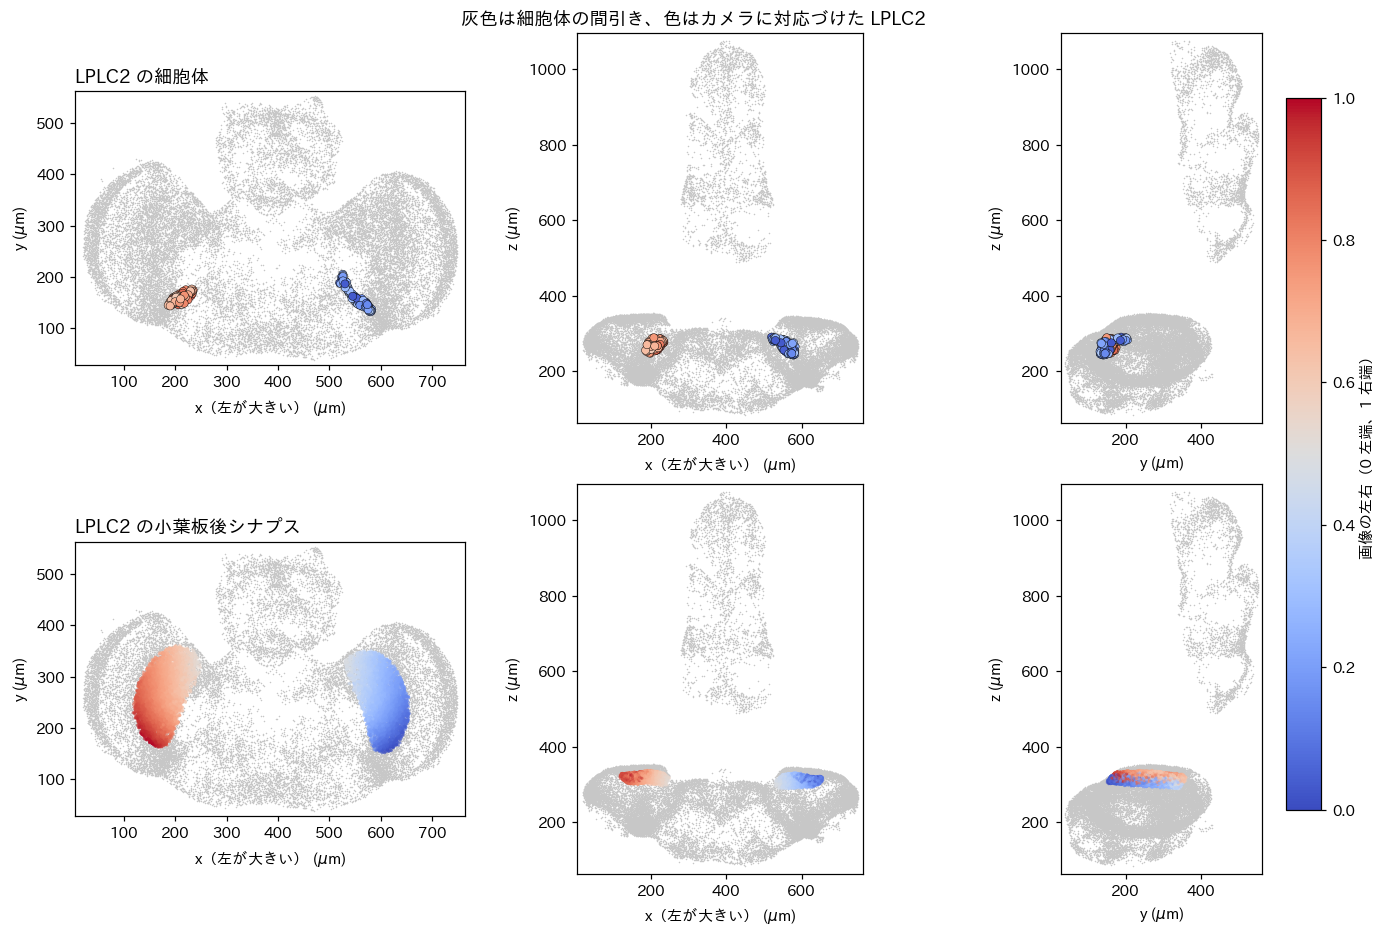

In [4]:
views = ((0, 1, "x（左が大きい）", "y"), (0, 2, "x（左が大きい）", "z"), (1, 2, "y", "z"))
limits = []
for i, j, _, _ in views:
    pad_i = 0.02 * (np.nanmax(soma[:, i]) - np.nanmin(soma[:, i]))
    pad_j = 0.02 * (np.nanmax(soma[:, j]) - np.nanmin(soma[:, j]))
    limits.append(
        (
            (np.nanmin(soma[:, i]) - pad_i, np.nanmax(soma[:, i]) + pad_i),
            (np.nanmin(soma[:, j]) - pad_j, np.nanmax(soma[:, j]) + pad_j),
        )
    )

fig, axes = plt.subplots(2, 3, figsize=(12.5, 8.2), constrained_layout=True)
layers = (
    (cell_soma, cell_u, 28, 1.0, "LPLC2 の細胞体"),
    (syn_um[syn_take], plate["u_syn"][syn_take], 4, 0.55, "LPLC2 の小葉板後シナプス"),
)
for row, (pts, color, size, alpha, title) in enumerate(layers):
    for col, ((i, j, xl, yl), (xlim, ylim)) in enumerate(zip(views, limits)):
        ax = axes[row, col]
        ax.scatter(bg[:, i], bg[:, j], s=1, c="0.78", linewidths=0, rasterized=True)
        ax.scatter(
            pts[:, i],
            pts[:, j],
            s=size,
            c=color,
            cmap="coolwarm",
            norm=norm,
            alpha=alpha,
            linewidths=0.3 if row == 0 else 0,
            edgecolors="k" if row == 0 else "none",
            rasterized=True,
        )
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel(f"{xl} ($\\mu$m)")
        ax.set_ylabel(f"{yl} ($\\mu$m)")
        if col == 0:
            ax.set_title(title, loc="left")
fig.colorbar(ScalarMappable(norm=norm, cmap="coolwarm"), ax=axes, fraction=0.03, pad=0.02).set_label(
    "画像の左右（0 左端、1 右端）"
)
fig.suptitle("灰色は細胞体の間引き、色はカメラに対応づけた LPLC2", y=1.02)
plt.show()


## カメラ画面の上の位置

黒点は LPLC2 の 1 本で、小葉板の後シナプスが載る列の平均である。点の平均は画面の縁まで届かない。1 本の樹状突起が複数の列にまたがるので、中心は端の列より内側に残る。灰点は、同じ式で置いた LC4 である。


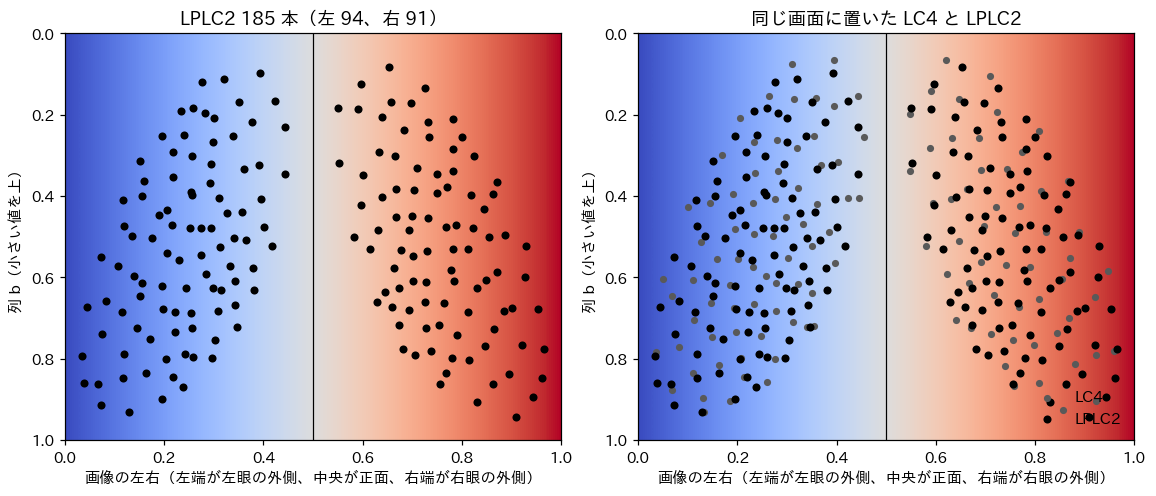

In [5]:
lc4_pack = np.load(LC4_CACHE)
lc4_cells = cell_table(
    lc4_pack["body"], lc4_pack["ab"], lc4_pack["side"], lc4_pack["left_ab"], lc4_pack["right_ab"]
)

fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.4), constrained_layout=True)
gradient = np.linspace(0, 1, 256)[None, :]
for ax in axes:
    ax.imshow(
        gradient,
        cmap="coolwarm",
        norm=norm,
        extent=(0, 1, 1, 0),
        aspect="auto",
        interpolation="bilinear",
    )
    ax.axvline(0.5, color="k", lw=0.8)
    ax.set_xlim(0, 1)
    ax.set_ylim(1, 0)
    ax.set_xlabel("画像の左右（左端が左眼の外側、中央が正面、右端が右眼の外側）")
    ax.set_ylabel("列 b（小さい値を上）")
axes[0].scatter(cell_u, cell_v, s=28, c="k", linewidths=0, zorder=3)
axes[0].set_title(
    f"LPLC2 {len(cell_u)} 本（左 {int((cell_side == 0).sum())}、右 {int((cell_side == 1).sum())}）"
)
axes[1].scatter(lc4_cells["u"], lc4_cells["v"], s=22, c="0.35", linewidths=0, label="LC4")
axes[1].scatter(cell_u, cell_v, s=28, c="k", linewidths=0, label="LPLC2")
axes[1].legend(frameon=False, loc="lower right")
axes[1].set_title("同じ画面に置いた LC4 と LPLC2")
plt.show()


## 3D 空間から画面への対応

下の平面は、カメラ画面を小葉板の手前に置いたものである。点は LPLC2 の 1 本で、小葉板の後シナプスの平均位置にある。線の先は、その細胞の列番号から決めた画面上の位置である。平面は見やすくするため z を 120 µm 下げてあり、光が集まる面ではない。


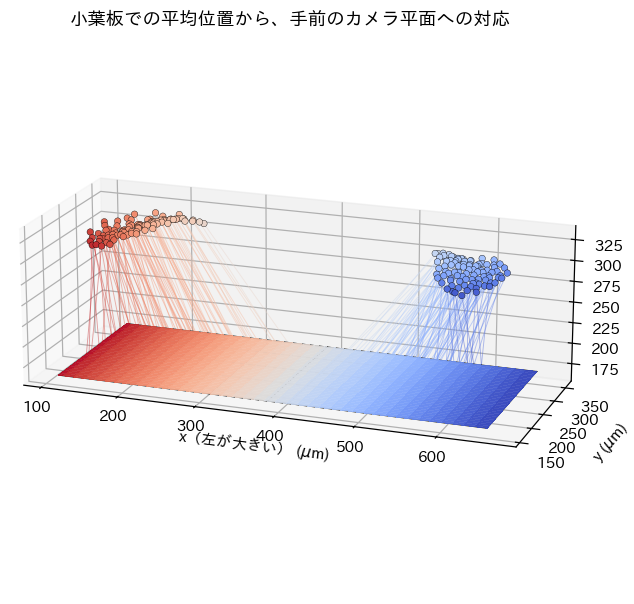

In [6]:
order = plate["order"]
syn_s = syn_um  # already ordered with the cells
cuts = np.r_[0, np.cumsum(plate["n"])[:-1]]
cell_xyz = np.add.reduceat(syn_s, cuts) / plate["n"][:, None]

xmin, xmax = float(syn_um[:, 0].min()), float(syn_um[:, 0].max())
ymin, ymax = float(syn_um[:, 1].min()), float(syn_um[:, 1].max())
z_plane = float(syn_um[:, 2].min()) - 120.0
uu = np.linspace(0.0, 1.0, 80)
vv = np.linspace(0.0, 1.0, 40)
uu_grid, vv_grid = np.meshgrid(uu, vv)
xx = xmax - uu_grid * (xmax - xmin)
yy = ymax - vv_grid * (ymax - ymin)
zz = np.full_like(xx, z_plane)
face = plt.cm.coolwarm(norm(uu_grid))
face[..., 3] = 0.92

fig = plt.figure(figsize=(9.6, 6.6))
ax = fig.add_subplot(1, 1, 1, projection="3d")
for point, cu, cv in zip(cell_xyz, cell_u, cell_v):
    ax.plot(
        [point[0], xmax - cu * (xmax - xmin)],
        [point[1], ymax - cv * (ymax - ymin)],
        [point[2], z_plane],
        color=plt.cm.coolwarm(norm(cu)),
        lw=0.6,
        alpha=0.45,
    )
ax.scatter(
    cell_xyz[:, 0],
    cell_xyz[:, 1],
    cell_xyz[:, 2],
    s=18,
    c=cell_u,
    cmap="coolwarm",
    norm=norm,
    edgecolors="k",
    linewidths=0.25,
    depthshade=False,
)
ax.plot_surface(xx, yy, zz, facecolors=face, shade=False, linewidth=0, antialiased=False)
border_u = np.array([0.0, 1.0, 1.0, 0.0, 0.0])
border_v = np.array([0.0, 0.0, 1.0, 1.0, 0.0])
ax.plot(
    xmax - border_u * (xmax - xmin),
    ymax - border_v * (ymax - ymin),
    np.full(5, z_plane),
    color="k",
    lw=0.7,
)
ax.plot(
    [xmax - 0.5 * (xmax - xmin), xmax - 0.5 * (xmax - xmin)],
    [ymax, ymin],
    [z_plane, z_plane],
    color="k",
    lw=0.6,
)
ax.view_init(elev=18, azim=-70)
span = np.array([xmax - xmin, ymax - ymin, float(syn_um[:, 2].max()) - z_plane])
ax.set_box_aspect(span / span.max())
ax.set_xlabel("x（左が大きい） ($\\mu$m)")
ax.set_ylabel("y ($\\mu$m)")
ax.set_zlabel("z ($\\mu$m)")
ax.set_title("小葉板での平均位置から、手前のカメラ平面への対応")
plt.show()


## 横の帯ごとに上下を引き伸ばした位置

画面の横を、片眼あたり 8 本の帯に切る。帯の中にある小葉板の列について、`b` が最小の列をその帯の上端、最大の列を下端に合わせ、間を均等に伸ばす。淡い点は伸ばしたあとの列、黒点は LPLC2 の平均位置に同じ伸縮をかけたものである。LC4 のノートと同じ操作である。


bands 8 per eye  columns 1698  stretched v 0.08–0.98


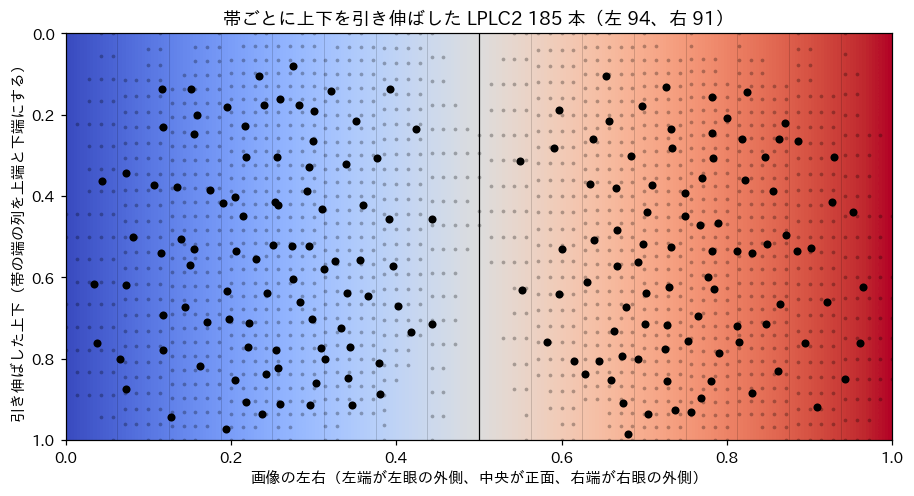

In [7]:
N_BINS = 8


def stretch_vertical(u_pts, v_pts, side_pts, left_ab, right_ab, n_bins=N_BINS):
    out = np.empty(len(v_pts), dtype=np.float64)
    for code, grid, u0, u1 in ((0, left_ab, 0.0, 0.5), (1, right_ab, 0.5, 1.0)):
        valid = grid[:, 0] >= 0
        cu, cv = image_uv(grid[valid], np.full(int(valid.sum()), code, dtype=np.int8), left_ab, right_ab)
        edges = np.linspace(u0, u1, n_bins + 1)
        col_bin = np.clip(np.digitize(cu, edges) - 1, 0, n_bins - 1)
        low = np.array([cv[col_bin == b].min() for b in range(n_bins)])
        high = np.array([cv[col_bin == b].max() for b in range(n_bins)])
        mask = side_pts == code
        pt_bin = np.clip(np.digitize(u_pts[mask], edges) - 1, 0, n_bins - 1)
        out[mask] = (v_pts[mask] - low[pt_bin]) / (high[pt_bin] - low[pt_bin])
    return out


col_u, col_v, col_side = [], [], []
for code, grid in ((0, pack["lop_left_ab"]), (1, pack["lop_right_ab"])):
    valid = grid[:, 0] >= 0
    uu, vv = image_uv(
        grid[valid],
        np.full(int(valid.sum()), code, dtype=np.int8),
        pack["lop_left_ab"],
        pack["lop_right_ab"],
    )
    col_u.append(uu)
    col_v.append(vv)
    col_side.append(np.full(int(valid.sum()), code, dtype=np.int8))
col_u = np.concatenate(col_u)
col_v = np.concatenate(col_v)
col_side = np.concatenate(col_side)
col_v_s = stretch_vertical(col_u, col_v, col_side, pack["lop_left_ab"], pack["lop_right_ab"])
cell_v_s = stretch_vertical(cell_u, cell_v, cell_side, pack["lop_left_ab"], pack["lop_right_ab"])
print(
    f"bands {N_BINS} per eye  columns {len(col_u)}  "
    f"stretched v {cell_v_s.min():.2f}–{cell_v_s.max():.2f}"
)

fig, ax = plt.subplots(figsize=(8.2, 4.4), constrained_layout=True)
ax.imshow(
    gradient,
    cmap="coolwarm",
    norm=norm,
    extent=(0, 1, 1, 0),
    aspect="auto",
    interpolation="bilinear",
)
ax.scatter(col_u, col_v_s, s=6, c="k", alpha=0.28, linewidths=0, zorder=2, rasterized=True)
ax.scatter(cell_u, cell_v_s, s=28, c="k", linewidths=0, zorder=3)
ax.axvline(0.5, color="k", lw=0.8)
for u0, u1 in ((0.0, 0.5), (0.5, 1.0)):
    edges = np.linspace(u0, u1, N_BINS + 1)
    ax.vlines(edges[1:-1], 0, 1, colors="k", lw=0.35, alpha=0.28, zorder=2)
ax.set_xlim(0, 1)
ax.set_ylim(1, 0)
ax.set_xlabel("画像の左右（左端が左眼の外側、中央が正面、右端が右眼の外側）")
ax.set_ylabel("引き伸ばした上下（帯の端の列を上端と下端にする）")
ax.set_title(
    f"帯ごとに上下を引き伸ばした LPLC2 {len(cell_u)} 本"
    f"（左 {int((cell_side == 0).sum())}、右 {int((cell_side == 1).sum())}）"
)
plt.show()


## 読み方

図に使ったのは小葉板の列である。185 本すべてが片側に収まり、左 94 本、右 91 本で、切り出しの本数と一致する。小葉の後シナプスから出した平均位置との差は、左右で平均 0.007、上下で平均 0.017 である。同じ細胞は、どちらの神経叢で見ても画面のほぼ同じ場所に落ちる。

列 `a` の外側は、左眼では x が大きく、右眼では x が小さい。LC4 の小葉の列と同じ向きなので、画面への式も同じである。平均位置は画面の縁まで届かない。樹状突起が複数の列にまたがるためで、端の画素はその端の列を持つ細胞に対応する。

定量の電流では、この小葉板の位置を LPLC2 の画面上の位置にする。小葉の位置で置き換えても、細胞の平均は上の差しか動かない。
